# 3. VIP – ưu tiên ôn tập theo nhầm lẫn thị giác (thuật toán đề xuất)

Khi thời gian có hạn, nên ôn từ nào trước? Cách thường làm: theo hạn ôn. **VIP** cộng thêm thông tin từ model
nhận diện ảnh (`BE/apps/algorithms/vip.py`, `vision.py`):

`VIP(u, w) = a·(1 − R) + b·Diff + c·(1 − Conf) + d·Confusion`

* `R`, `Diff` – xác suất còn nhớ và độ khó của từ với người học (FSRS, hoặc SM-2);
* `Conf` – độ tự tin trung bình của YOLO với lớp vật thể của từ;
* `Confusion` – tỉ lệ lớp đó bị nhận nhầm thành lớp khác: từ **confusion matrix** trên tập test nếu model đang dùng
  là model tự train; với model pretrained (không có tập test gắn box) thì từ **chính model đang dùng chạy trên
  ảnh từ vựng thật** (`vision.from_photos`). Cộng thêm các lần người học báo nhận diện sai.

Mặc định a, b, c, d = 0,4 · 0,25 · 0,15 · 0,2.

**Thực nghiệm:** mô phỏng người học (trí nhớ thật theo mô hình quên hàm mũ, *không* phải mô hình FSRS để không thiên vị),
mỗi ngày 8 từ mới và tối đa 25 lượt ôn; so sánh tỉ lệ nhớ cuối kỳ khi chọn từ ôn theo hạn và theo VIP.

> **Cách chạy:** mở bằng VS Code (hoặc Jupyter), chọn kernel **LingoPrism (BE venv)** rồi *Run All*. PostgreSQL phải đang chạy. Notebook dùng đúng mã nguồn của server (`BE/apps/algorithms`), kết quả được lưu vào database nên trang **Admin → Thuật toán AI** hiện ngay kết quả mới nhất. Mọi biểu đồ được lưu thêm thành ảnh PNG trong `AI/notebooks/figures/` để đưa vào báo cáo.

In [1]:
# Khởi tạo: nạp Django của BE/ (database + mã thuật toán thật của server) và matplotlib
import pathlib, sys
_here = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "AI/notebooks/lingoprism_setup.py").exists())
sys.path.insert(0, str(_here / "AI/notebooks"))
from lingoprism_setup import ROOT, init, save, table
init()

import random, time
import numpy as np
import matplotlib.pyplot as plt

Django OK – config.settings.dev | hình lưu ở D:\kicuoi\doantotnghiep\SnapLingua-main\AI\notebooks\figures


## 3.1 Tham số

In [2]:
# hồ sơ nhầm lẫn phải đến từ model server đang dùng: confusion matrix chỉ dùng khi nó là của model đó
import json
from apps.detection.models import ModelVersion
ACTIVE = ModelVersion.objects.filter(is_active=True).values_list("name", flat=True).first()
_cms = [c for c in (ROOT / "AI" / "runs").glob("*/report/confusion_matrix.json")
        if json.loads((c.parents[1] / "model_card.json").read_text(encoding="utf-8"))["name"] == ACTIVE]
CONFUSION = _cms[0] if _cms else None   # None -> model đang dùng chạy trên ảnh từ vựng thật
LEARNERS = 12   # số người học mô phỏng
DAYS = 60       # số ngày mô phỏng
print("Model đang dùng:", ACTIVE, "| nguồn nhầm lẫn:", CONFUSION or "ảnh từ vựng thật (vision.from_photos)")


Model đang dùng: yolov8m-oiv7-lingoprism | nguồn nhầm lẫn: D:\kicuoi\doantotnghiep\SnapLingua-main\AI\runs\oiv7-pretrained\report\confusion_matrix.json


## 3.2 Hồ sơ nhầm lẫn thị giác của các lớp vật thể

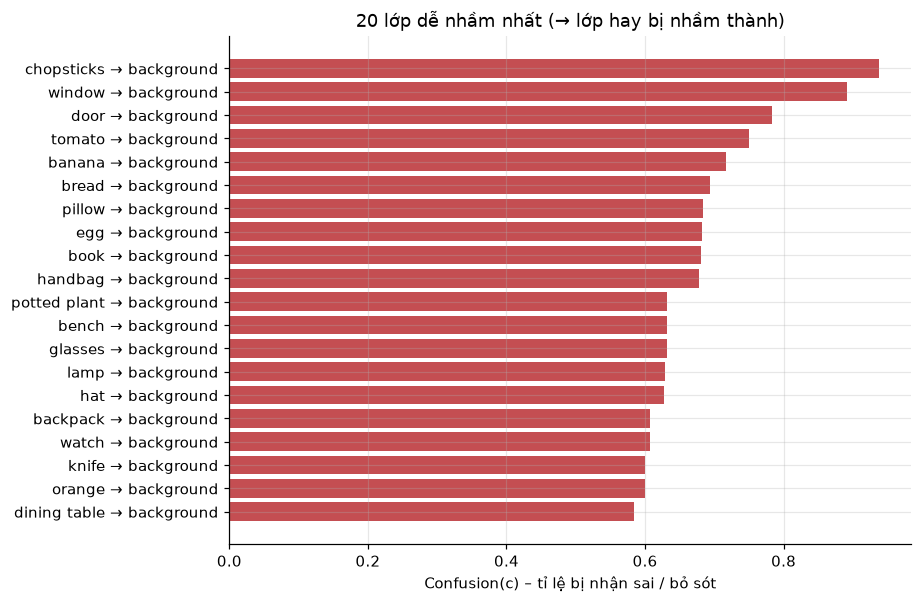

78 lớp, 51 lớp có Confusion ≥ 0,3


In [3]:
from apps.algorithms import experiments, vision, vip

profile = vision.build(str(CONFUSION) if CONFUSION else None)
top = sorted(profile.items(), key=lambda kv: -kv[1]["score"])[:20]
fig, ax = plt.subplots(figsize=(8, 6))
labels = [f"{k} → {max(v['confusion'], key=v['confusion'].get) if v['confusion'] else '-'}" for k, v in top]
ax.barh(labels[::-1], [v["score"] for _, v in top][::-1], color="#c44e52")
ax.set_xlabel("Confusion(c) – tỉ lệ bị nhận sai / bỏ sót")
ax.set_title("20 lớp dễ nhầm nhất (→ lớp hay bị nhầm thành)")
save(fig, "03_lop_de_nham")
plt.show()
print(f"{len(profile)} lớp, {sum(1 for v in profile.values() if v['score'] >= 0.3)} lớp có Confusion ≥ 0,3")

## 3.3 Điểm VIP của vài trường hợp

In [4]:
cases = {"từ dễ, nhớ tốt": {"forget": 0.1, "difficulty": 0.1, "confidence": 0.0, "confusion": 0.0},
         "từ dễ nhầm qua ảnh": {"forget": 0.1, "difficulty": 0.1, "confidence": 0.6, "confusion": 0.9},
         "từ sắp quên": {"forget": 0.9, "difficulty": 0.5, "confidence": 0.0, "confusion": 0.0}}
table([{"trường hợp": k, **c, "VIP": round(vip.score(c), 3)} for k, c in cases.items()])

trường hợp          forget  difficulty  confidence  confusion  VIP   
------------------  ------  ----------  ----------  ---------  ------
từ dễ, nhớ tốt      0.1000  0.1000      0.0000      0.0000     0.0650
từ dễ nhầm qua ảnh  0.1000  0.1000      0.6000      0.9000     0.3350
từ sắp quên         0.9000  0.5000      0.0000      0.0000     0.4850


## 3.4 Mô phỏng người học

1190 từ, 51 từ dễ nhầm – 2s
cấu hình        nhớ (mọi từ)  nhớ (từ dễ nhầm)  lượt ôn / người
--------------  ------------  ----------------  ---------------
SM-2            0.4449        0.2568            1377.8000      
SM-2 + VIP      0.3192        0.6212            1377.2000      
SM-2 + VIP lai  0.4398        0.3053            1376.3000      
FSRS            0.4537        0.3083            1376.5000      
FSRS + VIP      0.3778        0.7398            1376.4000      
FSRS + VIP lai  0.4745        0.3130            1375.5000      
Leitner         0.3684        0.1949            1345.6000      


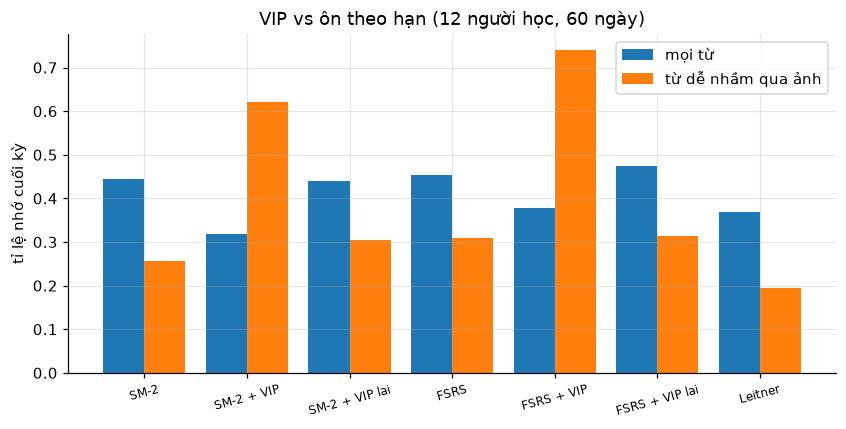

In [5]:
t0 = time.time()
run = experiments.vip(LEARNERS, DAYS)
res = run.results
print(f"{res['words']} từ, {res['confusable_words']} từ dễ nhầm – {time.time() - t0:.0f}s")
label = {("sm2", "due"): "SM-2", ("sm2", "vip"): "SM-2 + VIP", ("sm2", "vip_hybrid"): "SM-2 + VIP lai",
         ("fsrs", "due"): "FSRS", ("fsrs", "vip"): "FSRS + VIP", ("fsrs", "vip_hybrid"): "FSRS + VIP lai",
         ("leitner", "due"): "Leitner"}
rows = [{"cấu hình": label[(r["scheduler"], r["priority"])], "nhớ (mọi từ)": r["recall_all"],
         "nhớ (từ dễ nhầm)": r["recall_confusable"], "lượt ôn / người": r["reviews_per_learner"]} for r in res["rows"]]
table(rows)
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(rows))
ax.bar(x - 0.2, [r["nhớ (mọi từ)"] for r in rows], 0.4, label="mọi từ")
ax.bar(x + 0.2, [r["nhớ (từ dễ nhầm)"] for r in rows], 0.4, label="từ dễ nhầm qua ảnh")
ax.set_xticks(x, [r["cấu hình"] for r in rows], fontsize=8, rotation=15)
ax.set_ylabel("tỉ lệ nhớ cuối kỳ")
ax.set_title(f"VIP vs ôn theo hạn ({LEARNERS} người học, {DAYS} ngày)")
ax.legend()
save(fig, "03_vip_mo_phong")
plt.show()

**Đọc kết quả:**
* **VIP thuần** (xếp hoàn toàn theo điểm VIP) dồn lượt ôn cho các từ dễ nhầm: nhóm này tăng rất mạnh nhưng tỉ lệ nhớ
  chung giảm, vì số lượt ôn mỗi ngày có hạn.
* **VIP lai** (vẫn theo hạn ôn, VIP chỉ đẩy một từ sớm lên tối đa vài ngày) giữ tỉ lệ nhớ chung và vẫn cải thiện nhóm
  dễ nhầm. Đây là cách hệ thống đang dùng – được chọn tự động bởi notebook 8 (so sánh tổng hợp).